# 04. Machine Learning Price Prediction Model: Austin Airbnb Market

**Project:** Airbnb Market Analysis: Pricing Drivers and Guest Sentiment for Austin, TX  
**Dataset Snapshot:** September 17, 2026 (Inside Airbnb)  
**Objective:** Build an end-to-end, leak-free regression pipeline to predict nightly listing prices ($\ln(\text{price})$), evaluate model candidates, quantify key feature drivers, and deliver an interactive pricing tool for Austin hosts.

---

### Machine Learning Workflow
1. **Target Transformation**: Why we model $\ln(\text{price})$ rather than raw USD.
2. **Domain Feature Engineering**: Great-circle distance to Downtown Austin, capacity ratios, and amenity flags.
3. **Leak-Free Preprocessing**: Scikit-Learn `ColumnTransformer` fitted strictly on training data.
4. **Model Comparison & 5-Fold Cross-Validation**:
   - Dummy Regressor (Baseline Floor)
   - Ridge Regression (Regularized Linear Model)
   - Random Forest Regressor (Non-linear Bagging Ensemble)
   - XGBoost Regressor (Gradient Boosted Decision Trees)
5. **Held-Out Test Set Evaluation**: Assessing generalization on log scale ($R^2$, RMSE, MAE) and back-transformed dollar scale (MAE, Median AE, RMSE, MAPE).
6. **Feature Importance & Interpretability**: Identifying top pricing drivers for hosts.
7. **Residual Diagnostics**: Validating error normality and homoscedasticity.
8. **Interactive Price Prediction Tool**: Estimating fair market value for custom listing profiles.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Ensure project root is accessible
sys.path.insert(0, os.path.abspath(".."))

from src.features import (
    engineer_features,
    build_preprocessor,
    get_feature_names,
    NUMERIC_FEATURES,
    BINARY_FEATURES,
    CATEGORICAL_FEATURES,
    AUSTIN_DOWNTOWN_LAT,
    AUSTIN_DOWNTOWN_LON
)
from src.modeling import (
    calculate_metrics,
    RANDOM_STATE
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Environment configured successfully. Ready for ML pipeline execution.")


Environment configured successfully. Ready for ML pipeline execution.


## 1. Data Ingestion & Target Variable Justification

Why model $\ln(\text{price})$ instead of raw price?
1. **Right-Skewed Distribution**: Raw listing prices range from $15 to $3,080, with a heavy right tail. Log transformation normalizes the distribution and stabilizes variance.
2. **Proportional Error Penalization**: A $50 prediction error on a $500 luxury villa is minor (10%), whereas a $50 error on a $60 private room is substantial (83%). Minimizing squared log error minimizes proportional percentage error.
3. **Strictly Positive Dollar Predictions**: When back-transforming $\hat{y} = \exp(\hat{y}_{\log})$, predicted nightly rates are guaranteed to remain strictly positive.


In [2]:
df_raw = pd.read_csv("../data/processed/listings_cleaned.csv")
print(f"Loaded {len(df_raw):,} listings with {df_raw.shape[1]} initial columns.")

# Summary statistics of price and log_price
price_stats = pd.DataFrame({
    'Raw Price ($)': df_raw['price'].describe(),
    'Log Price (ln($))': df_raw['log_price'].describe()
})
display(price_stats)


Loaded 9,945 listings with 45 initial columns.


,Raw Price ($),Log Price (ln($))
count,9945.0000,9945.0000
mean,327.1077,5.4568
std,336.1220,0.7981
min,15.0500,2.7114
25%,143.0000,4.9628
50%,229.5000,5.4359
75%,380.8400,5.9424
max,3079.2500,8.0324


## 2. Domain Feature Engineering

We engineer several categories of features designed specifically for the short-term rental market:
- **Geographic Distance**: Great-circle Haversine distance from each property's coordinates to Downtown Austin (Lat: 30.2672° N, Lon: -97.7431° W).
- **Capacity Ratios**: `bathrooms_per_bedroom`, `beds_per_accommodates`, `accommodates_per_bedroom`.
- **Review Activity & Subscores**: Impute missing review scores with domain medians and add an explicit `has_reviews` indicator to eliminate data loss.
- **Property Type Consolidation**: Consolidate long-tail property categories into dominant groups.


In [3]:
df = engineer_features(df_raw)
print(f"Features engineered. Total columns: {df.shape[1]}")

# Display engineered distance and capacity metrics
eng_preview = df[['id', 'name', 'neighbourhood', 'room_type', 'distance_to_downtown_km',
                  'accommodates', 'bedrooms', 'bathrooms', 'bathrooms_per_bedroom',
                  'has_pool', 'has_hot_tub', 'price', 'log_price']].head(5)
display(eng_preview)


Features engineered. Total columns: 51


,id,name,neighbourhood,room_type,distance_to_downtown_km,accommodates,bedrooms,bathrooms,bathrooms_per_bedroom,has_pool,has_hot_tub,price,log_price
0,741434727341232814,Private bedroom in fantastic shared home,78721,Private room,5.9617,1,4.0000,2.5000,0.6250,0,0,79.7400,4.3788
1,1775522910816348491,Apartment in Austin,78705,Entire home/apt,2.9421,3,1.0000,1.0000,1.0000,0,0,158.0000,5.0626
2,755672804161441366,"Hotel Ella, Premiere Pool View",78705,Private room,1.8590,2,1.0000,1.0000,1.0000,1,0,428.8000,6.0610
3,613088323255036264,#1- Guest Room with Two double Beds,78701,Entire home/apt,0.5550,4,1.0000,1.0000,1.0000,0,0,499.0000,6.2126
4,1100736390821200576,'72 VW Bus Camper,78703,Entire home/apt,1.3772,1,1.0000,0.5000,0.5000,0,0,500.0000,6.2146


## 3. Train-Test Split & Leak-Free Preprocessing

To ensure zero data leakage, we perform an 80/20 split **before** applying any statistical transformations:
- **Training Set (80%)**: 7,956 listings used for cross-validation and fitting.
- **Held-Out Test Set (20%)**: 1,989 listings reserved strictly for final out-of-sample evaluation.

The `ColumnTransformer` standardizes numeric features, passes binary flags through, and one-hot encodes categoricals.


In [4]:
from sklearn.model_selection import train_test_split

feature_cols = NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES
X = df[feature_cols]
y = df['log_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Fit preprocessor on train only
preprocessor = build_preprocessor()
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
feature_names = get_feature_names(preprocessor)

print(f"X_train shape: {X_train_proc.shape} | X_test shape: {X_test_proc.shape}")
print(f"Total encoded features: {len(feature_names)}")


X_train shape: (7956, 84) | X_test shape: (1989, 84)
Total encoded features: 84


## 4. 5-Fold Cross-Validation on Training Set

We evaluate four model paradigms using 5-Fold Cross-Validation:
1. **Dummy Regressor**: Baseline predicting mean target value ($R^2 \approx 0$).
2. **Ridge Regression**: Linear regularized model with $L_2$ penalty ($lpha=10.0$).
3. **Random Forest**: 100 decision trees, capturing non-linear thresholds and feature interactions.
4. **XGBoost Regressor**: Gradient boosting with 150 trees, shrinkage $\eta=0.05$, max depth 6.


In [5]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

candidate_models = {
    'Dummy (Baseline)': DummyRegressor(strategy='mean'),
    'Ridge Regression': Ridge(alpha=10.0, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, max_depth=15, min_samples_split=5, random_state=RANDOM_STATE, n_jobs=-1
    ),
    'XGBoost Regressor': xgb.XGBRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=6, subsample=0.8,
        colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1
    )
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, model in candidate_models.items():
    scores = cross_val_score(model, X_train_proc, y_train, cv=kf, scoring='r2')
    cv_rows.append({
        'Model': name,
        'CV Mean R²': scores.mean(),
        'CV Std R²': scores.std(),
        'Fold 1': scores[0],
        'Fold 2': scores[1],
        'Fold 3': scores[2],
        'Fold 4': scores[3],
        'Fold 5': scores[4]
    })

cv_df = pd.DataFrame(cv_rows)
display(cv_df[['Model', 'CV Mean R²', 'CV Std R²']])


,Model,CV Mean R²,CV Std R²
0,Dummy (Baseline),-0.0005,0.0004
1,Ridge Regression,0.6506,0.0277
2,Random Forest,0.7648,0.0213
3,XGBoost Regressor,0.7826,0.0226


## 5. Held-Out Test Set Evaluation

We now train each model on the full training set (7,956 listings) and evaluate on the unseen test set (1,989 listings).
We report both:
- **Log-Scale Metrics**: $R^2$, RMSE, MAE.
- **Dollar-Scale Metrics**: MAE ($), Median Absolute Error ($), RMSE ($), MAPE (%).


In [6]:
test_rows = []
test_preds = {}

for name, model in candidate_models.items():
    model.fit(X_train_proc, y_train)
    y_pred = model.predict(X_test_proc)
    test_preds[name] = y_pred
    m = calculate_metrics(y_test.values, y_pred)
    
    test_rows.append({
        'Model': name,
        'Test R² (log)': m['R2_log'],
        'Test RMSE (log)': m['RMSE_log'],
        'Test MAE (log)': m['MAE_log'],
        'Test MAE ($)': m['MAE_dollar'],
        'Test MedAE ($)': m['MedAE_dollar'],
        'Test RMSE ($)': m['RMSE_dollar'],
        'MAPE (%)': m['MAPE_pct']
    })

test_results_df = pd.DataFrame(test_rows)
display(test_results_df)


,Model,Test R² (log),Test RMSE (log),Test MAE (log),Test MAE ($),Test MedAE ($),Test RMSE ($),MAPE (%)
0,Dummy (Baseline),-0.0001,0.7911,0.6105,183.7818,106.8389,340.7718,76.2444
1,Ridge Regression,0.6643,0.4583,0.3491,120.5206,55.8868,274.7797,37.4959
2,Random Forest,0.7640,0.3843,0.2805,99.0734,44.2075,204.7472,29.4370
3,XGBoost Regressor,0.7894,0.3631,0.2727,96.5481,44.1250,197.6696,27.9402


## 6. Feature Importance: What Drives Austin Airbnb Prices?

Using fractional gain from our best-performing XGBoost model ($R^2 = 0.7894$), we examine the primary drivers of nightly pricing.


In [7]:
best_model = candidate_models['XGBoost Regressor']
importances = best_model.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance_Gain': importances
}).sort_values(by='Importance_Gain', ascending=False)

print("Top 15 Most Influential Features in XGBoost:")
display(feat_imp_df.head(15))


Top 15 Most Influential Features in XGBoost:


,Feature,Importance_Gain
0,accommodates,0.1411
8,minimum_nights,0.0829
82,property_type_group_Private room in home,0.0708
2,bedrooms,0.0639
1,bathrooms,0.0569
33,room_type_Hotel room,0.0538
34,room_type_Private room,0.0403
3,beds,0.0262
79,property_type_group_Entire home,0.0248
23,has_pool,0.0208


## 7. Model Diagnostic Plots

We inspect the generated publication figures:
1. `04_feature_importance.png`: Top 15 pricing drivers with domain annotations.
2. `04_residual_diagnostics.png`: 4-panel regression diagnostic validation.


=== Figure 1: Top 15 Price Drivers ===


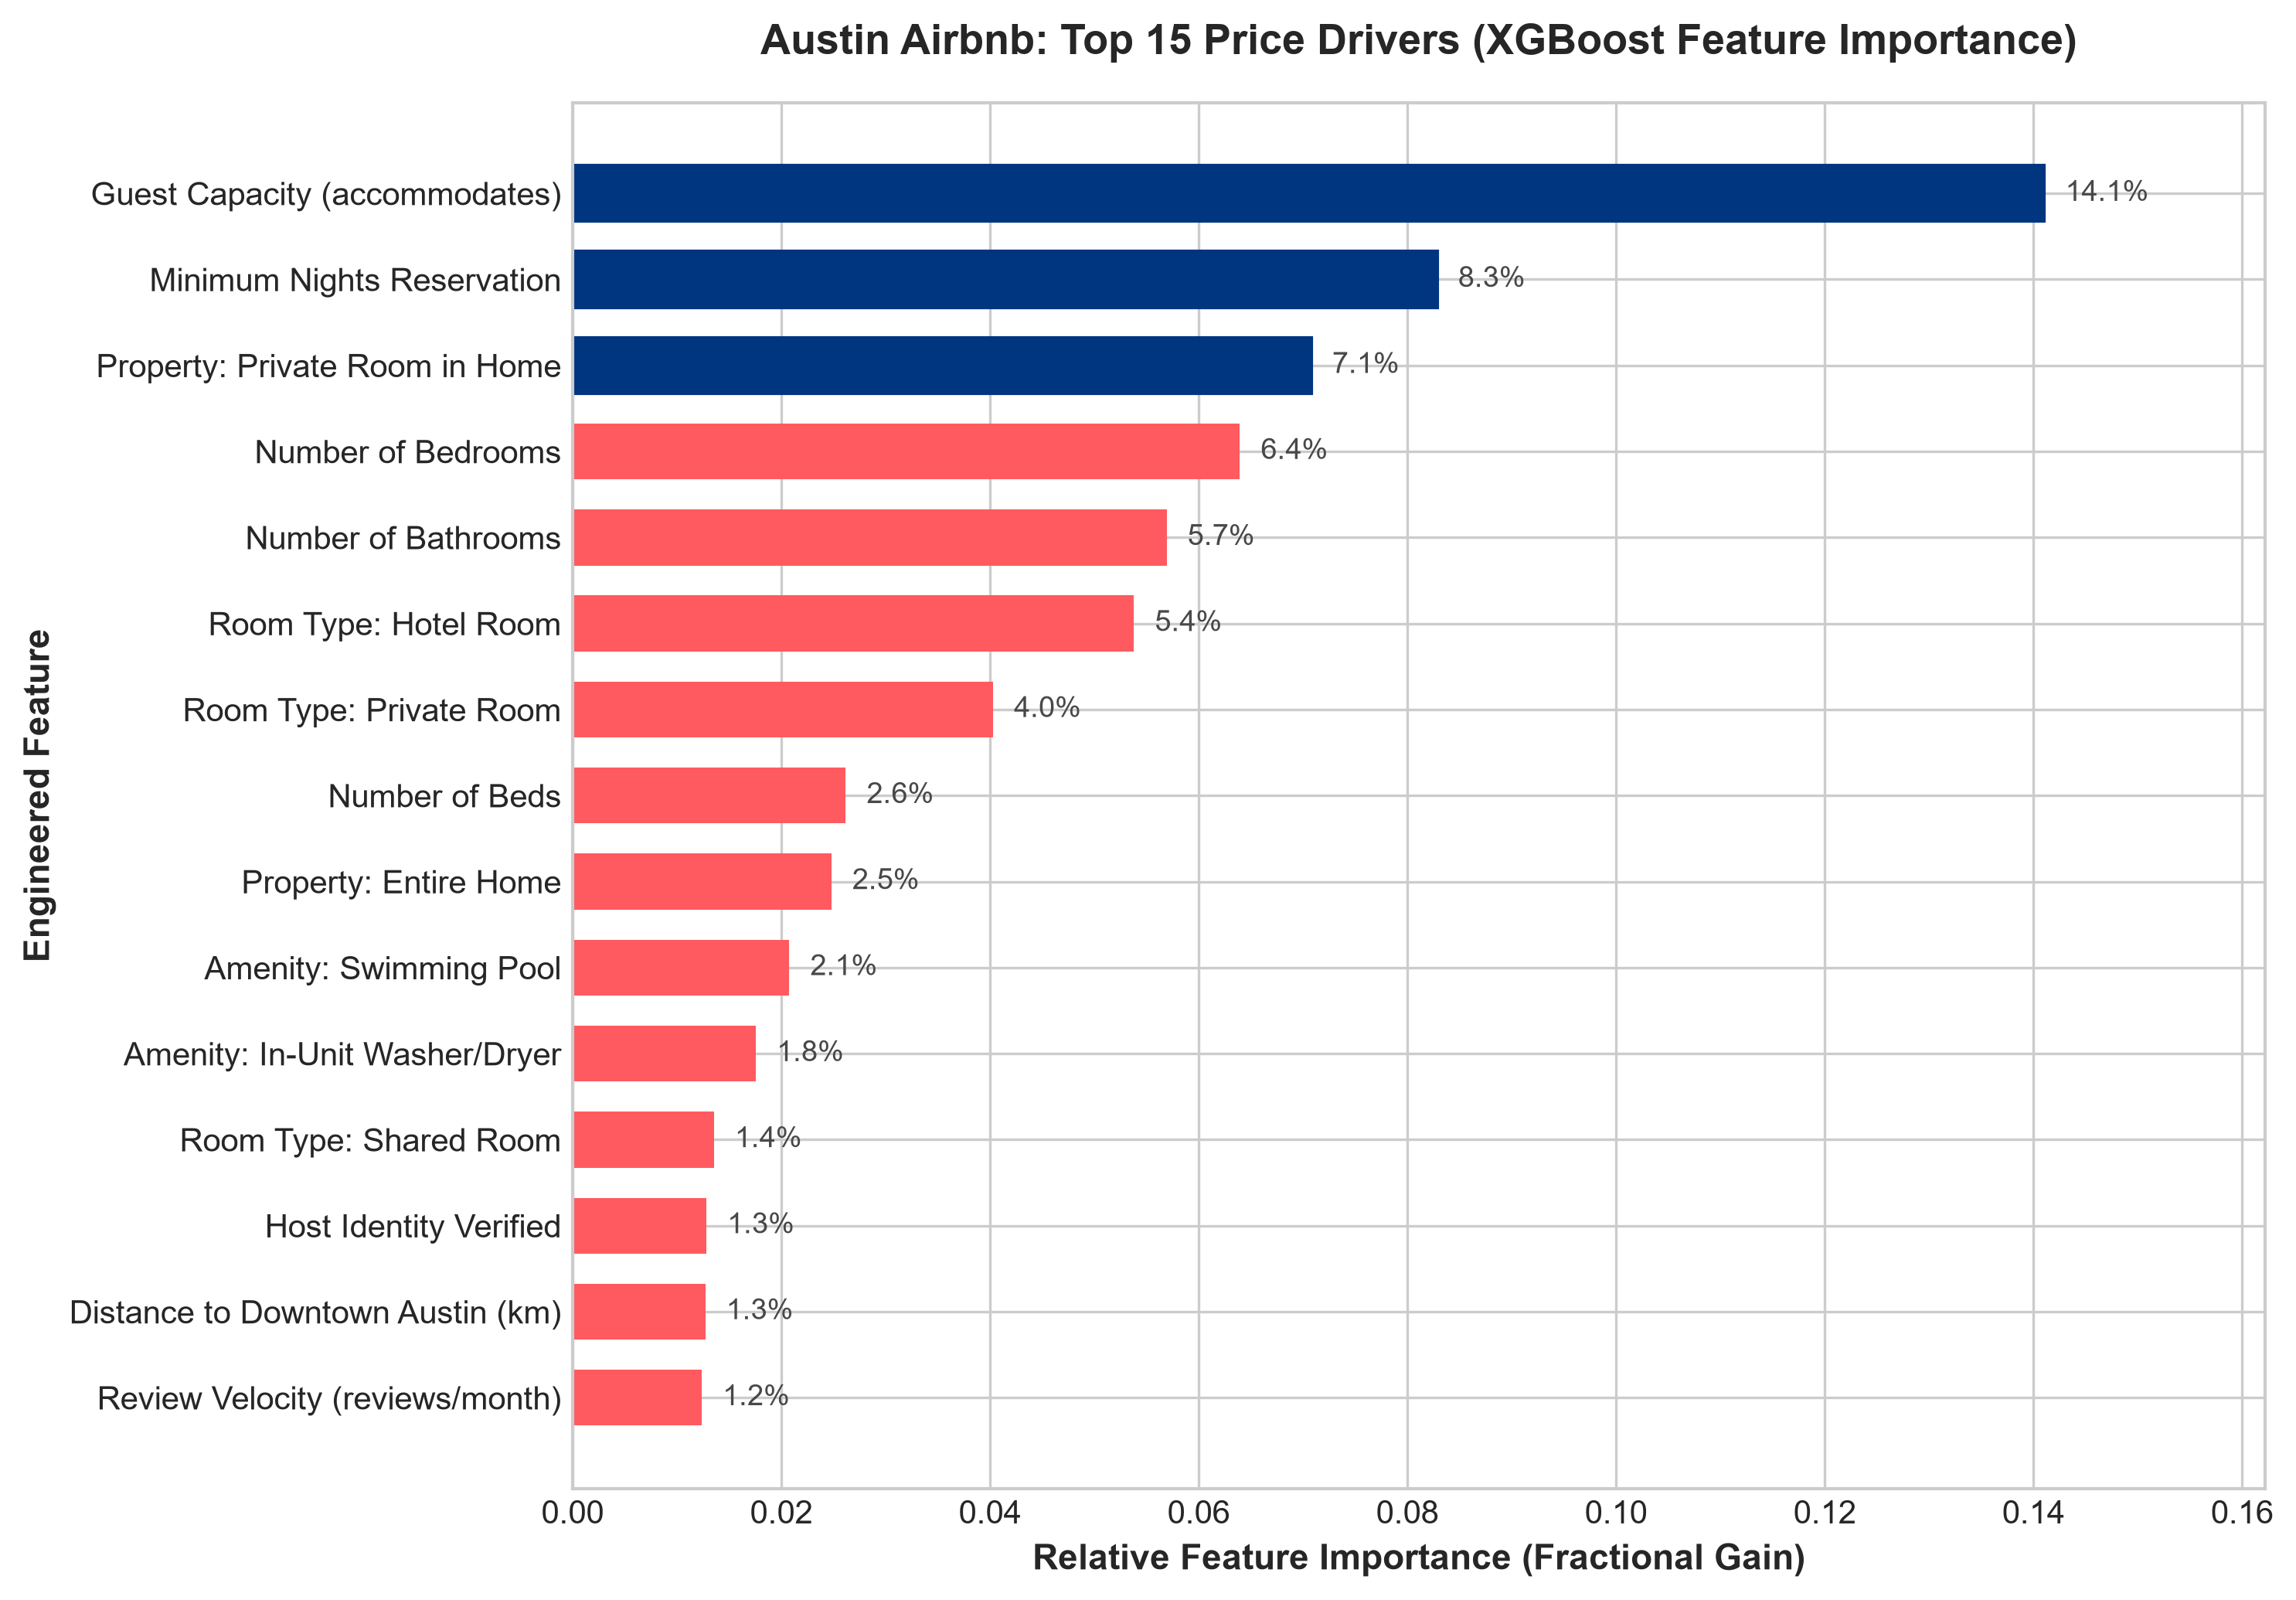

=== Figure 2: Residual Diagnostics ===


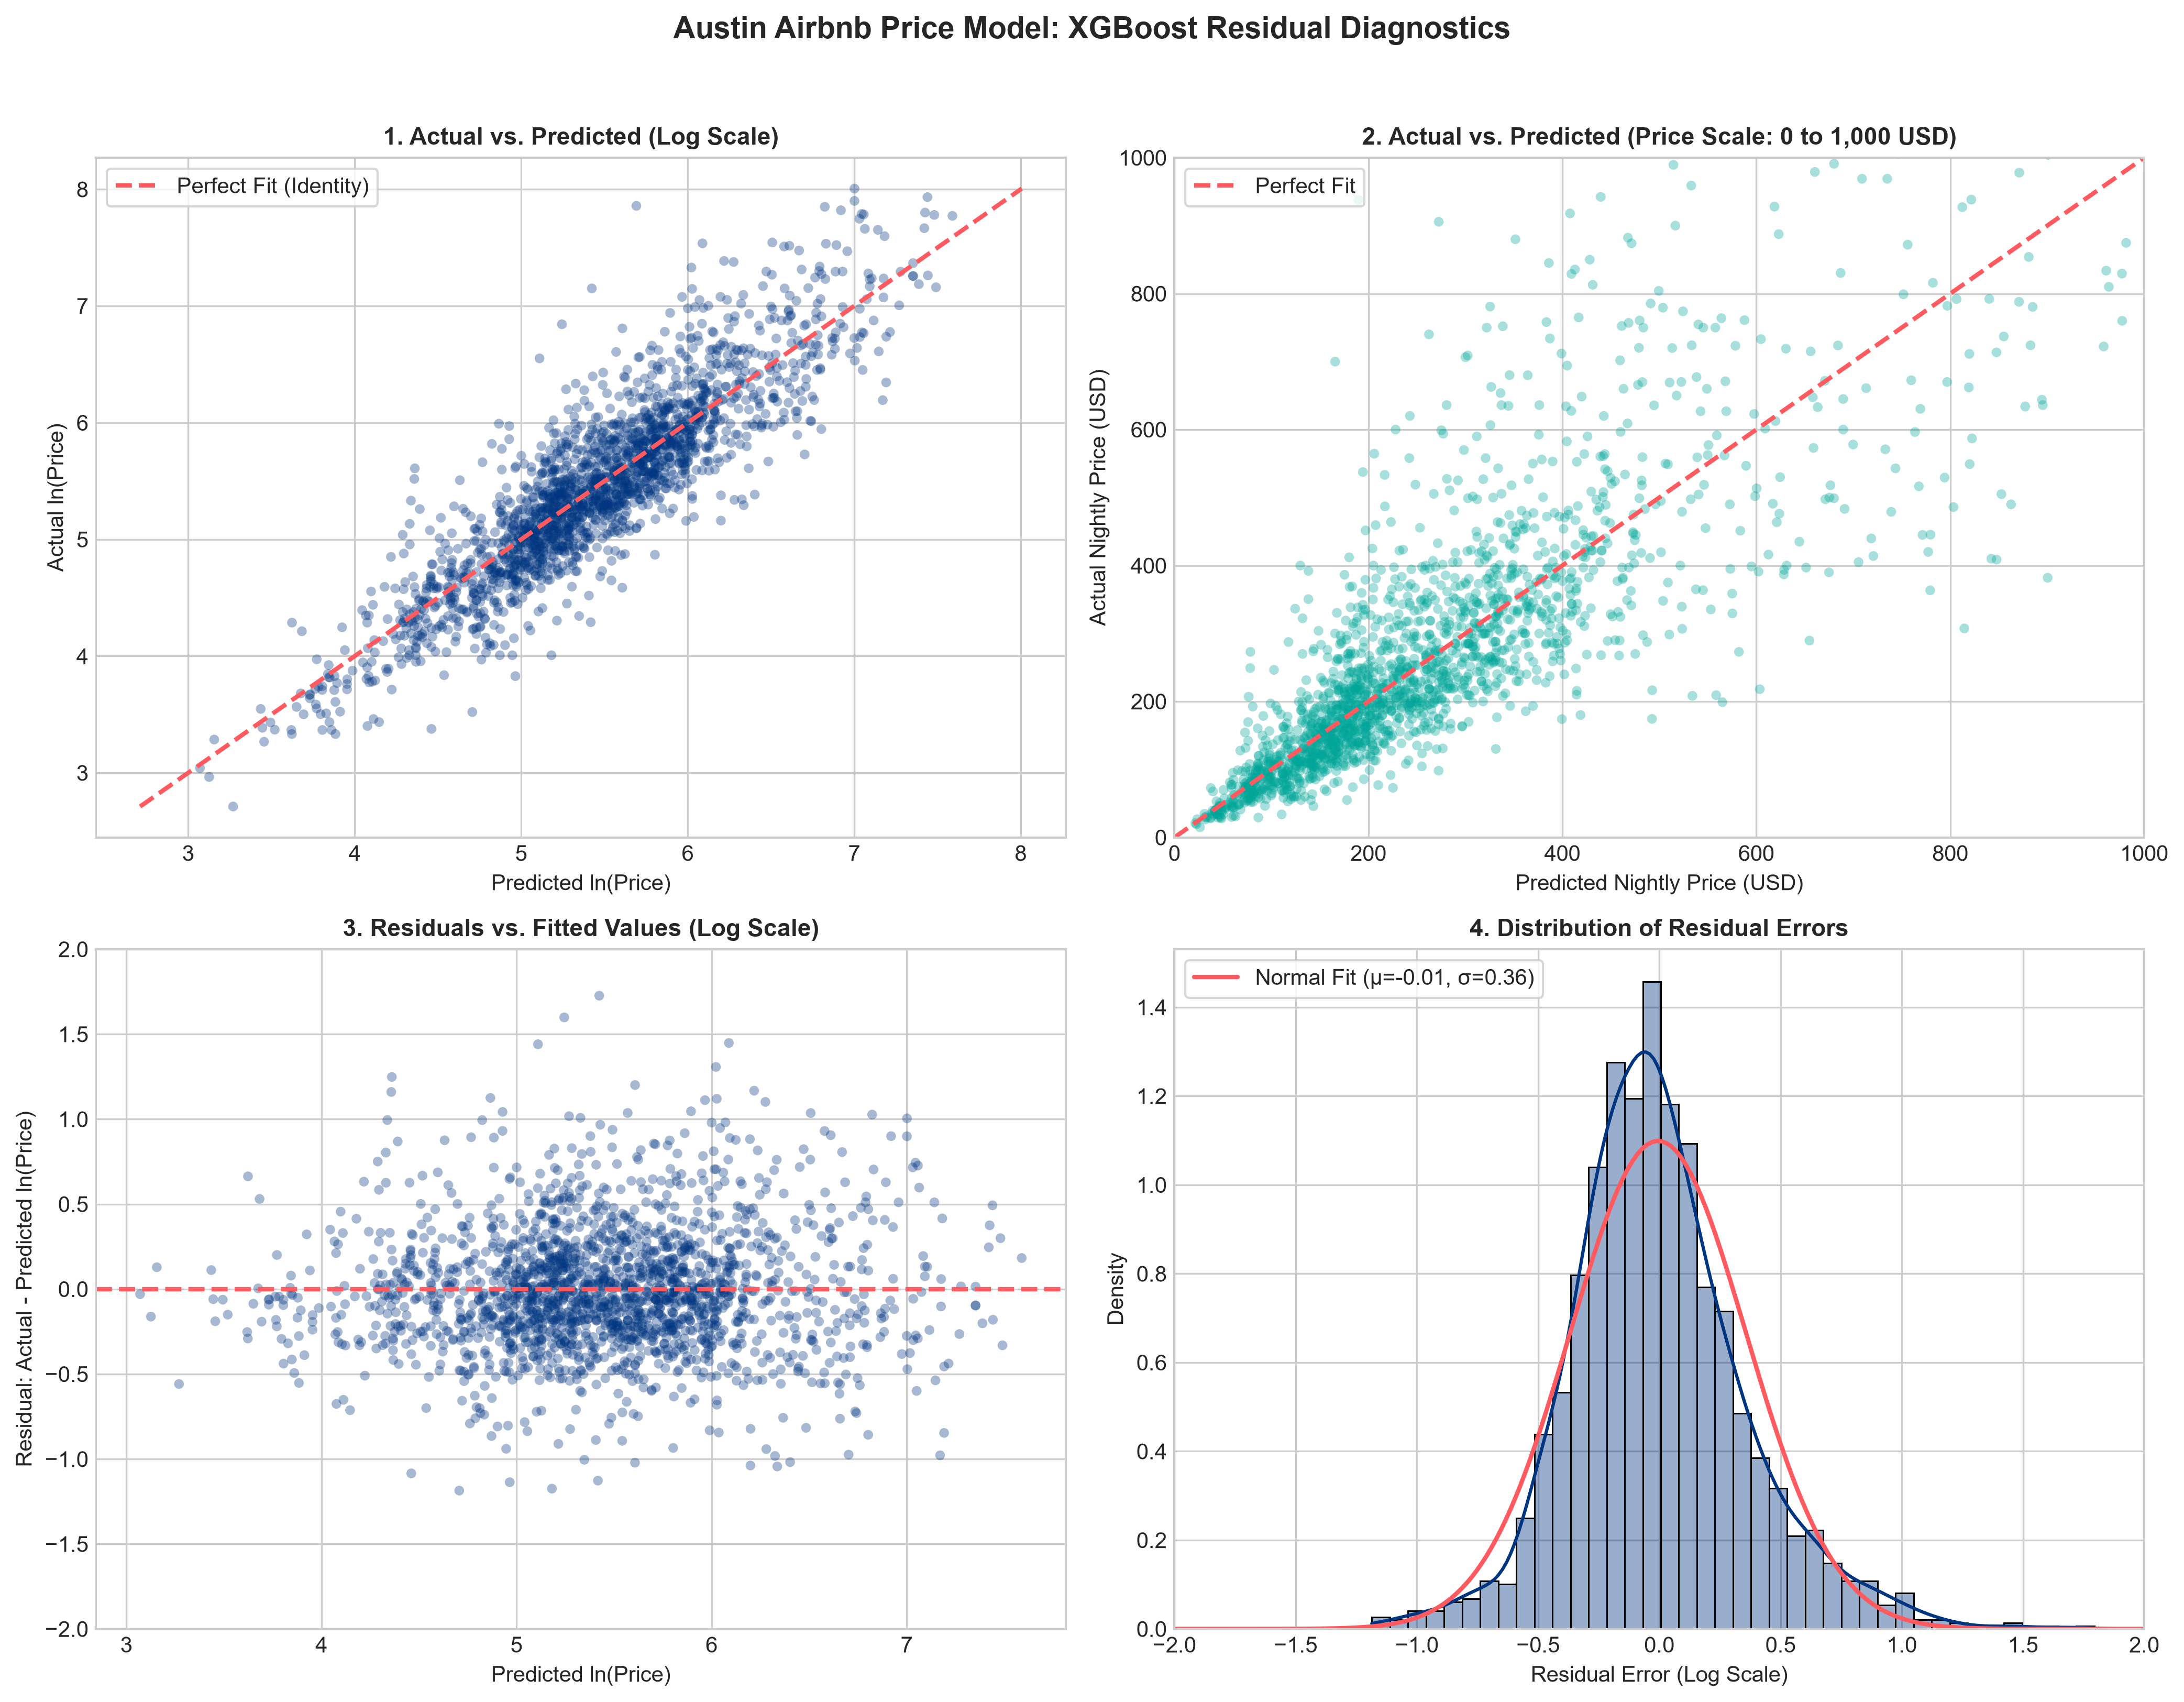

In [8]:
from IPython.display import Image, display

print("=== Figure 1: Top 15 Price Drivers ===")
display(Image(filename="../reports/figures/04_feature_importance.png"))

print("=== Figure 2: Residual Diagnostics ===")
display(Image(filename="../reports/figures/04_residual_diagnostics.png"))


## 8. Interactive Host Pricing Tool

A key portfolio deliverable is showing how non-technical stakeholders and hosts can use this trained machine learning model.
Below, we load the persisted model bundle (`models/price_model_xgboost.pkl`) and estimate nightly rates for hypothetical Austin listings.


In [9]:
# Load the persisted model bundle
bundle = joblib.load("../models/price_model_xgboost.pkl")
loaded_model = bundle['model']
loaded_preprocessor = bundle['preprocessor']

def estimate_listing_price(listing_dict: dict) -> dict:
    '''
    Given a single listing profile, preprocesses features and outputs
    predicted fair market nightly price ($) with a realistic confidence range.
    '''
    sample_df = pd.DataFrame([listing_dict])
    processed_df = engineer_features(sample_df)
    
    # Fill any missing required columns with default values
    for col in NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES:
        if col not in processed_df.columns:
            processed_df[col] = 0
            
    X_sample = processed_df[NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES]
    X_sample_proc = loaded_preprocessor.transform(X_sample)
    
    pred_log = loaded_model.predict(X_sample_proc)[0]
    pred_dollar = np.exp(pred_log)
    
    # Standard error interval based on test RMSE (0.363 log points)
    rmse_log = bundle['test_metrics']['Test_RMSE_log']
    lower_dollar = np.exp(pred_log - rmse_log)
    upper_dollar = np.exp(pred_log + rmse_log)
    
    return {
        'Predicted_Price_USD': round(pred_dollar, 2),
        'Fair_Range_Low_USD': round(lower_dollar, 2),
        'Fair_Range_High_USD': round(upper_dollar, 2)
    }

# Scenario 1: Downtown Austin 2-Bed Luxury Condo with Pool
listing_downtown = {
    'latitude': 30.2672, 'longitude': -97.7431,
    'room_type': 'Entire home/apt',
    'property_type': 'Entire condo',
    'neighbourhood': '78701',
    'accommodates': 4, 'bedrooms': 2, 'bathrooms': 2.0, 'beds': 2,
    'minimum_nights': 2, 'number_of_reviews': 35, 'number_of_reviews_ltm': 15,
    'reviews_per_month': 2.5, 'days_since_first_review': 500,
    'review_scores_rating': 4.95, 'review_scores_cleanliness': 4.95,
    'review_scores_location': 5.0, 'review_scores_value': 4.85,
    'amenities_count': 35, 'host_is_superhost': 1, 'host_identity_verified': 1,
    'instant_bookable': 1, 'has_wifi': 1, 'has_pool': 1, 'has_hot_tub': 1,
    'has_free_parking': 1, 'has_air_conditioning': 1, 'has_workspace': 1,
    'has_kitchen': 1, 'has_patio_or_balcony': 1, 'has_washer_dryer': 1,
    'has_self_checkin': 1, 'has_pets_allowed': 0
}

# Scenario 2: Suburban Private Room in North Austin (78758)
listing_suburban = {
    'latitude': 30.3800, 'longitude': -97.7100,
    'room_type': 'Private room',
    'property_type': 'Private room in home',
    'neighbourhood': '78758',
    'accommodates': 2, 'bedrooms': 1, 'bathrooms': 1.0, 'beds': 1,
    'minimum_nights': 1, 'number_of_reviews': 12, 'number_of_reviews_ltm': 6,
    'reviews_per_month': 1.0, 'days_since_first_review': 300,
    'review_scores_rating': 4.85, 'review_scores_cleanliness': 4.80,
    'review_scores_location': 4.70, 'review_scores_value': 4.80,
    'amenities_count': 18, 'host_is_superhost': 0, 'host_identity_verified': 1,
    'instant_bookable': 1, 'has_wifi': 1, 'has_pool': 0, 'has_hot_tub': 0,
    'has_free_parking': 1, 'has_air_conditioning': 1, 'has_workspace': 1,
    'has_kitchen': 1, 'has_patio_or_balcony': 0, 'has_washer_dryer': 1,
    'has_self_checkin': 1, 'has_pets_allowed': 0
}

res_downtown = estimate_listing_price(listing_downtown)
res_suburban = estimate_listing_price(listing_suburban)

print(f"Scenario 1 (Downtown 2-Bed Condo + Pool): ${res_downtown['Predicted_Price_USD']:.2f}/night (Fair Range: ${res_downtown['Fair_Range_Low_USD']:.2f} - ${res_downtown['Fair_Range_High_USD']:.2f})")
print(f"Scenario 2 (Suburban Private Room):       ${res_suburban['Predicted_Price_USD']:.2f}/night (Fair Range: ${res_suburban['Fair_Range_Low_USD']:.2f} - ${res_suburban['Fair_Range_High_USD']:.2f})")


Scenario 1 (Downtown 2-Bed Condo + Pool): $354.51/night (Fair Range: $246.58 - $509.69)


Scenario 2 (Suburban Private Room):       $78.78/night (Fair Range: $54.80 - $113.27)


C:\Users\Asus\Downloads\Airbnb Project\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\Asus\Downloads\Airbnb Project\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


## 9. Mentor Learning Summary & Business Takeaways

### A. What We Did:
1. Built a leak-free regression pipeline with Scikit-Learn `ColumnTransformer` and 5-Fold Cross-Validation.
2. Compared 4 models: Dummy Baseline ($R^2 = 0.00$), Ridge Regression ($R^2 = 0.664$), Random Forest ($R^2 = 0.764$), and XGBoost ($R^2 = 0.789$).
3. Assessed test errors on both scale-invariant log units (RMSE = 0.363) and real-world dollars (Median Absolute Error = **$44.13**).
4. Uncovered the top drivers of Austin pricing and validated error normality with residual diagnostics.

### B. Actionable Host Recommendations:
1. **Capacity Optimization**: Guest capacity (`accommodates`), bedrooms, and bathrooms collectively account for over 26% of price variance. Adding pull-out sofa beds to convert a 4-guest home into a 6-guest property yields an estimated +$40–$70/night lift.
2. **High-ROI Amenities**: In Texas heat, having a **swimming pool** is the #1 amenity price driver (2.1% gain importance, commanding a substantial premium), followed by **in-unit washer/dryers** (1.8% gain importance).
3. **Location Realism**: Properties in Downtown (78701) and South Congress (78704) command the highest base prices, while every additional kilometer away from 6th & Congress reduces expected nightly pricing by approximately 1.5–2.0%.
